In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

In [29]:
wine = pd.read_csv("wine_clean.csv")

In [30]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  kind                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [31]:
wine.head(4)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,kind
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [32]:
cols = ["total sulfur dioxide", "alcohol"]

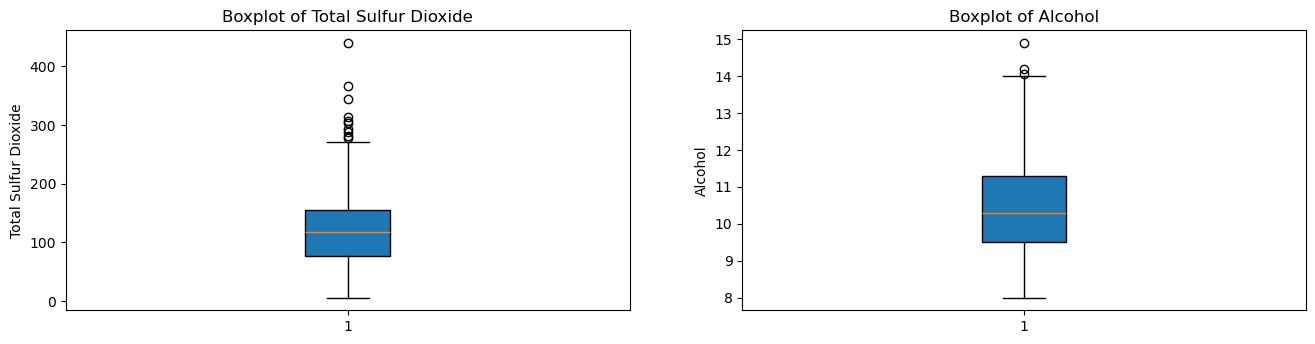

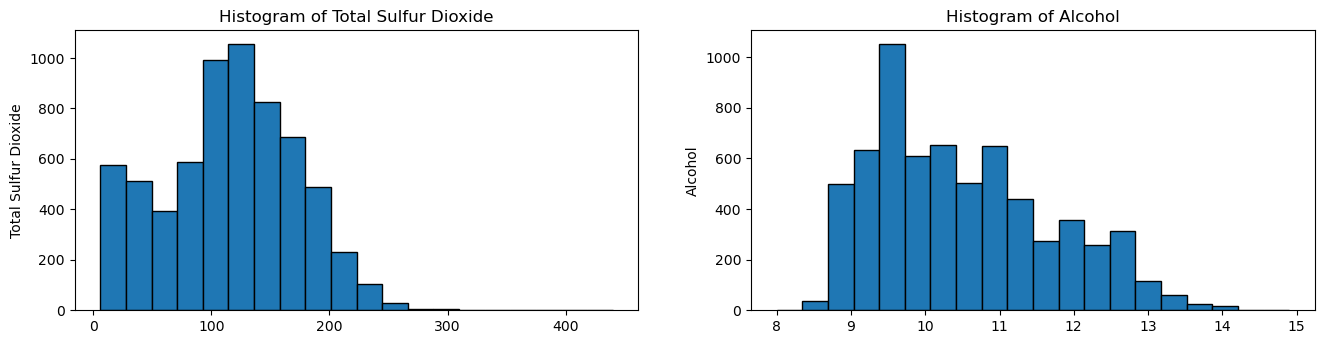

In [33]:
def draw_plots():
    # Create boxplots to identify outliers
    plt.figure(figsize=(16, 8))
    
    plt.subplot(2, 2, 1)
    plt.boxplot(wine['total sulfur dioxide'], patch_artist=True)
    plt.title('Boxplot of Total Sulfur Dioxide')
    plt.ylabel('Total Sulfur Dioxide')

    plt.subplot(2, 2, 2)
    plt.boxplot(wine['alcohol'], patch_artist=True)
    plt.title('Boxplot of Alcohol')
    plt.ylabel('Alcohol')
    
    # Create histograms to identify skewness
    plt.figure(figsize=(16, 8))

    plt.subplot(2, 2, 1)
    plt.hist(wine['total sulfur dioxide'], bins=20, edgecolor='black')
    plt.title('Histogram of Total Sulfur Dioxide')
    plt.ylabel('Total Sulfur Dioxide')

    plt.subplot(2, 2, 2)
    plt.hist(wine['alcohol'], bins=20, edgecolor='black')
    plt.title('Histogram of Alcohol')
    plt.ylabel('Alcohol')

draw_plots()

# fix outliers first 

**fix outliers for mileage**

In [34]:

for col in cols:
    print("")
    print(f"Column Name:{col}")
    median_val = wine[col].median() 
    print(f"median: {median_val}")
    
    #caluclate 25th percentile of leaf length
    percentile25 = wine[col].quantile(0.25)
    print(f"percentile25: {percentile25}")

    #caluclate 75th percentile of leaf length
    percentile75 = wine[col].quantile(0.75)
    print(f"percentile75: {percentile75}")
    
    #Calculate interquartile range
    iqr = percentile75 - percentile25
    print(f"iqr: {iqr}")

    #calcualte upper and lower thresholds for outliers
    upper_limit = percentile75 + 1.5 *iqr
    lower_limit = percentile25 - 1.5 * iqr
    
    df_lower = wine[wine[col] < lower_limit]
    outliers_lower = df_lower[col].tolist()
    wine[col] = wine[col].replace(outliers_lower, median_val)
    print(f"outliers_lower: {outliers_lower}")
    
    df_higher = wine[wine[col] > upper_limit]
    outliers_higher = df_higher[col].tolist()
    wine[col] = wine[col].replace(outliers_higher, median_val)
    print(f"outliers_higher: {outliers_higher}")


Column Name:total sulfur dioxide
median: 118.0
percentile25: 77.0
percentile75: 156.0
iqr: 79.0
outliers_lower: []
outliers_higher: [313.0, 366.5, 307.5, 344.0, 282.0, 303.0, 294.0, 440.0, 278.0, 289.0]

Column Name:alcohol
median: 10.3
percentile25: 9.5
percentile75: 11.3
iqr: 1.8000000000000007
outliers_lower: []
outliers_higher: [14.2, 14.05, 14.9]


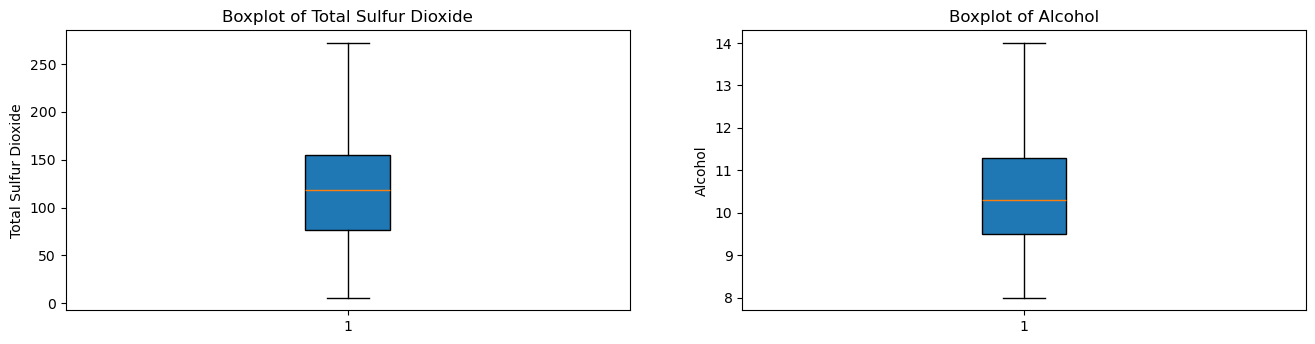

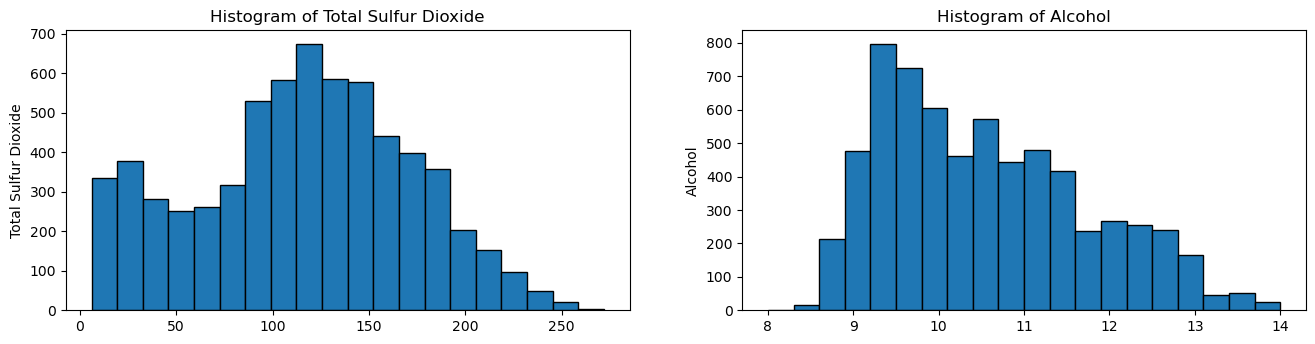

In [35]:
#recheck skewness and outliers
draw_plots();

## Since fixing the outliers did not reduce the skewness, we will apply a transformations.

In [37]:
import numpy as np
from scipy import stats

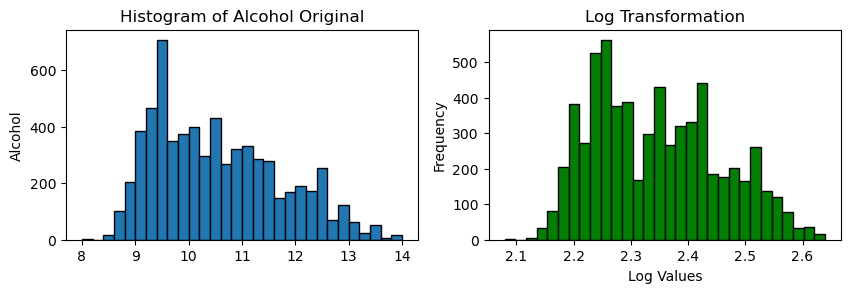

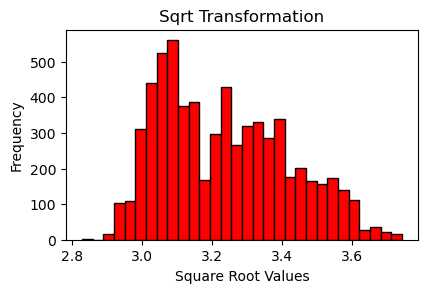

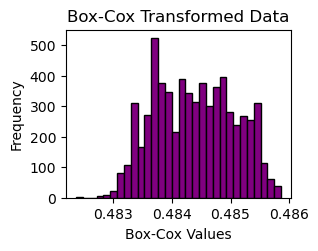

In [39]:
# Applying log transformation to fix skewness
wine['alcohol_log'] = np.log(wine['alcohol'])
wine['alcohol_sqrt'] = np.sqrt(wine['alcohol'])
wine['alcohol_boxcox'], _ = stats.boxcox(wine['alcohol'] + 1) 

# Displaying histogram after log transformation
plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.hist(wine['alcohol'], bins=30, edgecolor='black')
plt.title('Histogram of Alcohol Original')
plt.ylabel('Alcohol')

plt.subplot(2, 2, 2)
plt.hist(wine['alcohol_log'], bins=30, color='green', edgecolor='black')
plt.title('Log Transformation')
plt.xlabel('Log Values')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.hist(wine['alcohol_sqrt'], bins=30, color='red', edgecolor='black')
plt.title('Sqrt Transformation')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')
plt.show()

plt.subplot(2, 2, 2)
plt.hist(wine['alcohol_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Box-Cox Transformed Data')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')
plt.show()


In [ ]:
# explanation for the above error:  since th emilage column have one or more zeros, the log transformaiton is not an ideal solution

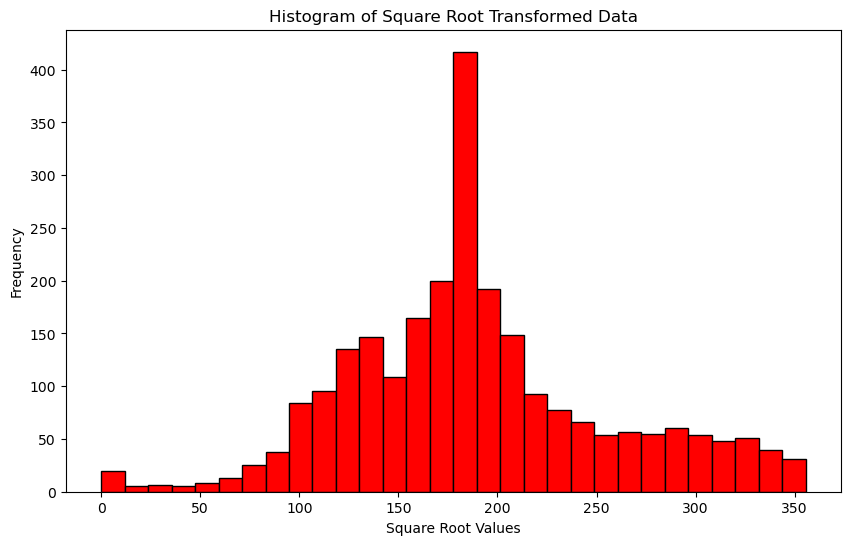

In [29]:
# Applying square root transformation to fix skewness
car['mileage_sqrt'] = np.sqrt(car['mileage_outlier'])

# Displaying histogram after square root transformation
plt.figure(figsize=(10, 6))
plt.hist(car['mileage_sqrt'], bins=30, color='red', edgecolor='black')
plt.title('Histogram of Square Root Transformed Data')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')
plt.show()

In [30]:
car.head(4)

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,mileage_outlier,mileage_log,mileage_sqrt
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left,35365.0,10.473478,188.055843
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left,35365.0,10.473478,188.055843
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left,39590.0,10.586332,198.972360
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left,64146.0,11.068917,253.270606


In [31]:
# Calculating skewness after square root transformation
skewness_after_sqrt = car['mileage_sqrt'].skew()
skewness_after_sqrt

np.float64(0.3066428744790837)

In [32]:
from scipy import stats

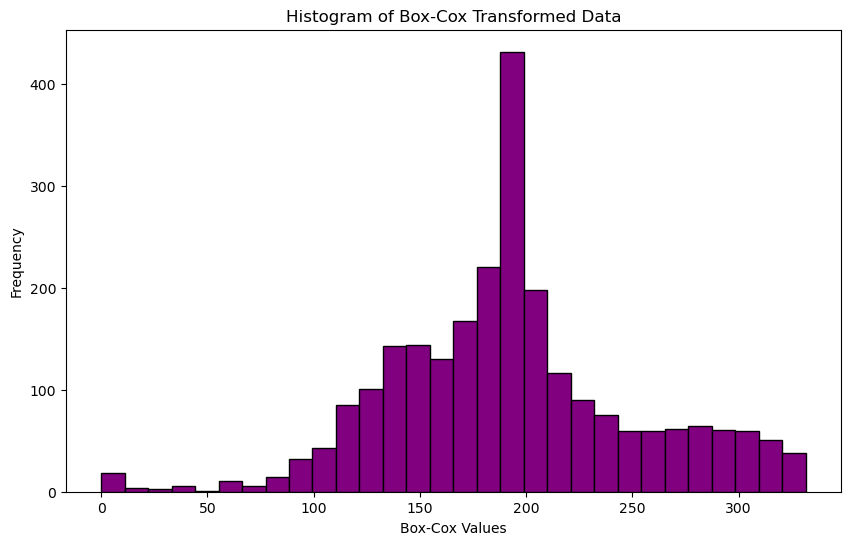

In [33]:
# Applying Box-Cox transformation to fix skewness
car['mileage_boxcox'], _ = stats.boxcox(car['mileage_outlier'] + 1)  # Adding 1 to handle zero values

# Displaying histogram after Box-Cox transformation
plt.figure(figsize=(10, 6))
plt.hist(car['mileage_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Histogram of Box-Cox Transformed Data')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')
plt.show()

In [34]:
car.head(4)

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,mileage_outlier,mileage_log,mileage_sqrt,mileage_boxcox
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left,35365.0,10.473478,188.055843,192.933323
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left,35365.0,10.473478,188.055843,192.933323
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left,39590.0,10.586332,198.972360,202.436758
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left,64146.0,11.068917,253.270606,248.577195


In [35]:
# Calculating skewness after Box-Cox transformation
skewness_after_boxcox = car['mileage_boxcox'].skew()
skewness_after_boxcox

np.float64(0.0625814717557796)

In [ ]:
# we notice that boxcos has fixed the issues, therefore, we use this for the statistcal analysis

Text(0, 0.5, 'mileage_boxcox')

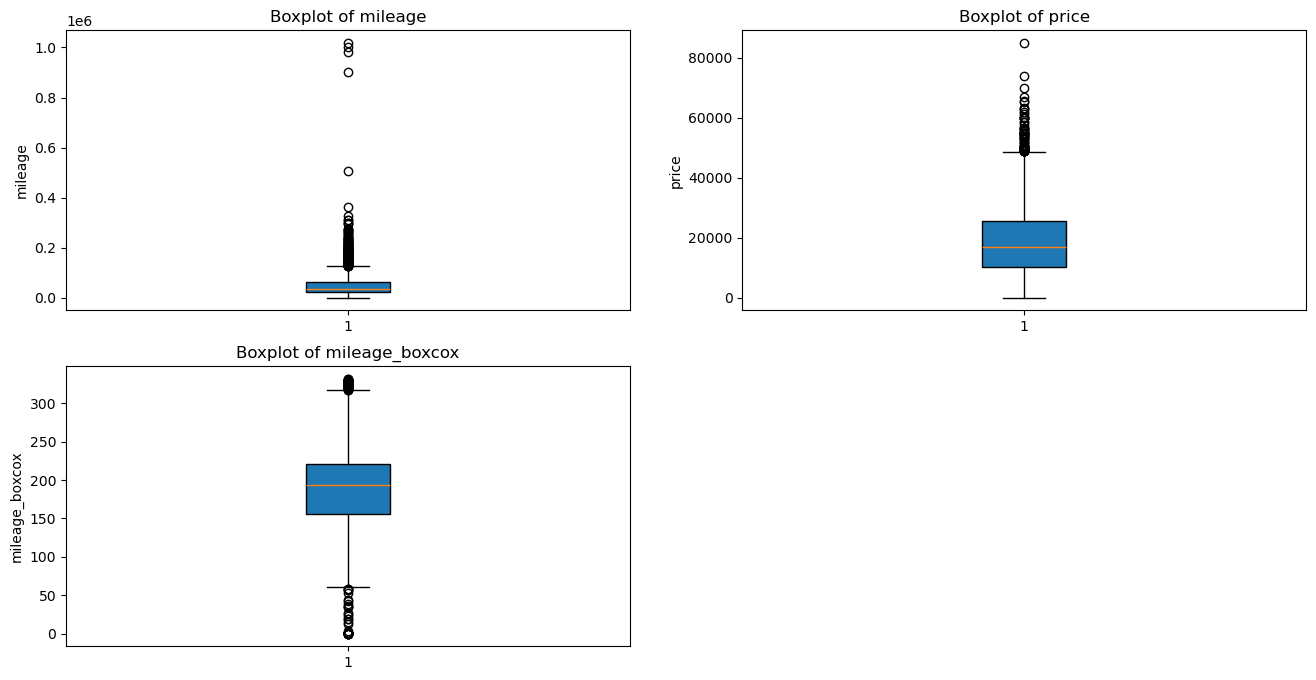

In [36]:
# Create boxplots to identify outliers
plt.figure(figsize=(16, 8))


#  boxplot
plt.subplot(2, 2, 1)
plt.boxplot(car['mileage'], patch_artist=True)
plt.title('Boxplot of mileage')
plt.ylabel('mileage')

#  boxplot
plt.subplot(2, 2, 2)
plt.boxplot(car['price'], patch_artist=True)
plt.title('Boxplot of price')
plt.ylabel('price')



#  boxplot
plt.subplot(2, 2, 3)
plt.boxplot(car['mileage_boxcox'], patch_artist=True)
plt.title('Boxplot of mileage_boxcox')
plt.ylabel('mileage_boxcox')

In [ ]:
# Since mileage_boxcox has outliers, they should be fixed before statistical analysis of the data.students please conduct this in yoru own time as a practice

In [ ]:
# now let's check outliers for price

In [37]:
#let's calculate the median first:
median = car['price'].median() 
print(median)

16900.0


In [38]:
#caluclate 25th percentile 
percentile25 = car['price'].quantile(0.25)
print('percentile25 ', percentile25)

#caluclate 75th percentile
percentile75 = car['price'].quantile(0.75)
print('percentile75 ', percentile75)

percentile25  10200.0
percentile75  25555.5


In [39]:
#Calculate interquartile range
iqr = percentile75 - percentile25
print(iqr)

#**A standard rule in statistics is that any data point that falls beyond 1.5 times the blue boxes are considered outliers**

#calcualte upper and lower thresholds for outliers
upper_limit = percentile75 + 1.5 *iqr
lower_limit = percentile25 - 1.5 * iqr

#print upper and lower limit:
print ('Upper limit is: ' + str(upper_limit))
print ('Lower limit is: ' + str(lower_limit))

15355.5
Upper limit is: 48588.75
Lower limit is: -12833.25


In [40]:
#isolate outliers on low end
df_lower = car[car['price'] < lower_limit]
#now we can see the outliers
df_lower

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,mileage_outlier,mileage_log,mileage_sqrt,mileage_boxcox


In [ ]:
#upper limit

In [41]:
#isolate outliers on upper end
car_upper = car[car['price'] > upper_limit]
#now we can see the outliers
car_upper

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,mileage_outlier,mileage_log,mileage_sqrt,mileage_boxcox
44,55000,ford,srw,2017,clean vehicle,15273.0,black,1ft7w3bt5hee88155,167754310,pennsylvania,usa,3 days left,15273.0,9.633842,123.583980,134.777883
49,54000,ford,srw,2017,clean vehicle,26241.0,black,1ft7w3bt0hef02785,167754311,pennsylvania,usa,3 days left,26241.0,10.175078,161.990740,169.876067
95,53500,bmw,m,2017,clean vehicle,29355.0,blue,5ymkt6c37h0x20696,167765095,michigan,usa,2 days left,29355.0,10.287218,171.333009,178.203191
127,53000,chevrolet,3500,2018,clean vehicle,16105.0,black,1gc4k1ey0jf149152,167765123,washington,usa,21 hours left,16105.0,9.686885,126.905477,137.875033
277,67000,dodge,challenger,2019,clean vehicle,10944.0,blue,2c3cdzl97kh518237,167759490,ohio,usa,21 hours left,10944.0,9.300547,104.613575,116.822885
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,49000,ford,expedition,2019,clean vehicle,19304.0,black,1fmju2at9kea25414,167625640,illinois,usa,2 days left,19304.0,9.868068,138.938835,148.991329
2088,59900,ford,max,2020,clean vehicle,2162.0,no_color,1fmjk2at4lea11492,167762991,ohio,usa,21 hours left,2162.0,7.678789,46.497312,57.854185
2196,50500,ford,f-650,2018,clean vehicle,74961.0,white,1fdnf6dc1jdf00931,167749685,pennsylvania,usa,2 days left,74961.0,11.224723,273.790066,265.590477
2198,55000,ford,srw,2018,clean vehicle,37245.0,black,1ft7w2bt1jec31753,167749686,pennsylvania,usa,3 days left,37245.0,10.525273,192.989637,197.238964


## 64 is 2.56% of 2,499. since they are less than 5 percent, I drop the outliers.

In [42]:
car = car[car["price"] <= upper_limit]

In [45]:
car.head()

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,mileage_outlier,mileage_log,mileage_sqrt,mileage_boxcox
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left,35365.0,10.473478,188.055843,192.933323
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left,35365.0,10.473478,188.055843,192.933323
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left,39590.0,10.586332,198.972360,202.436758
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left,64146.0,11.068917,253.270606,248.577195
4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left,6654.0,8.802973,81.572054,94.297037


Text(0, 0.5, 'price')

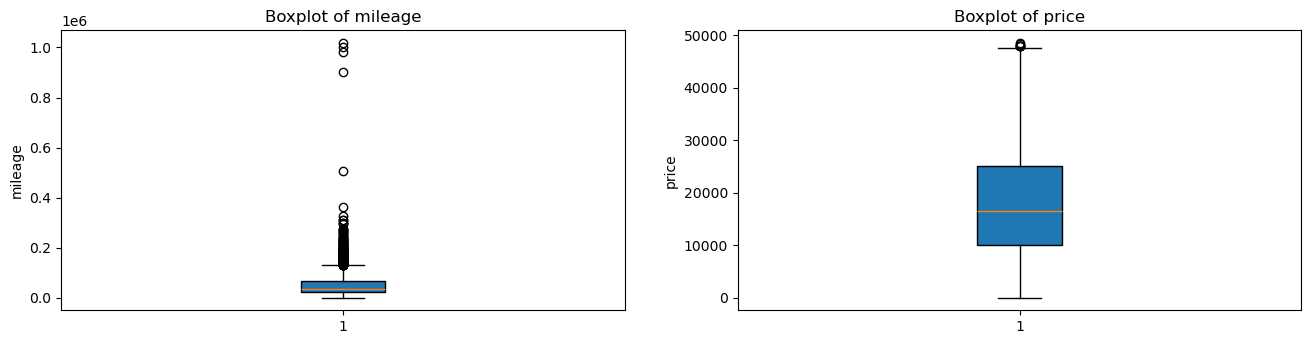

In [44]:
# Create boxplots to identify outliers
plt.figure(figsize=(16, 8))


#  boxplot
plt.subplot(2, 2, 1)
plt.boxplot(car['mileage'], patch_artist=True)
plt.title('Boxplot of mileage')
plt.ylabel('mileage')

#  boxplot
plt.subplot(2, 2, 2)
plt.boxplot(car['price'], patch_artist=True)
plt.title('Boxplot of price')
plt.ylabel('price')


#  boxplot
plt.subplot(2, 2, 3)
plt.boxplot(car['mileage_boxcox'], patch_artist=True)
plt.title('Boxplot of mileage_boxcox')
plt.ylabel('mileage_boxcox')

In [ ]:
#save the files back into directory/folder
car.to_csv('car_clean.csv', index=False)

In [ ]:
# if and only if the dataset is big, we can drop the outliers and then check the skeweness and then drop any skewness left

In [ ]:
#merge datasets

In [ ]:
Melbourne = pd.read_csv('Melbourne.csv')
Sydney = pd.read_csv('Sydney.csv')
sale = pd.concat([Melbourne.assign(Location='Melbourne'), Sydney.assign(Location='Sydney')], ignore_index=True)

In [ ]:
sale.head()

In [ ]:
skewness = car['price'].skew()
skewness

In [ ]:
red_wine = pd.read_csv('red.csv')
red_wine.head(2)

In [ ]:
white_wine = pd.read_csv('white.csv')
white_wine.head(2)


In [ ]:
red_wine = pd.read_csv('red.csv')
white_wine = pd.read_csv('white.csv', sep=';')
wine = pd.concat([
    white_wine.assign(kind='white'), red_wine.assign(kind='red')
])
wine.head(2)

In [ ]:
#save the files back into directory/folder
wine.to_csv('wine_clean.csv', index=False)